# Tutorial 6. Wastewater disinfection: a chlorine contact tank

![A chlorine contact tank](../tutorials/images/t06_hero.png)

**Scope:** chemical engineering, environmental engineering. **Components:**
`Species`, `Reaction`, `Dose`, `Outflow`, `Accumulator`, `MixedReactor`,
`TanksInSeries`.

## The asset

The last stage of a wastewater treatment plant. Secondary effluent flows at
0.35 m³/s through a serpentine contact tank where sodium hypochlorite is dosed.
Chlorine decays on its own (first order) and is consumed by residual organics
(second order, chlorine plus organics). The permit requires at least 0.2 mg/L
of residual chlorine at the outfall, and the operator wants to dose as little as
possible. Two questions:

- **How much to dose?** For the permit residual at the outfall, what hypochlorite
  flow is needed, and how much chlorine leaves per day?
- **Mixing matters.** The tank is built as a serpentine so that it behaves like a
  plug-flow reactor. How much worse would one stirred basin of the same volume do?

![P&ID](../tutorials/images/t06_pd.png)

The P&ID shows the dosing tank `TK-201`, the dosing pump `P-201` under flow
control, the four contact cells and the residual analyser `AT-202` at the
outfall.

## Step 1. The kinetics, in a beaker

Before the reactor, the chemistry on its own. A `Species` is an amount in a
volume; a `Reaction` draws from and delivers to species at the mass-action rate.
Units are mol, m³ and s. Chlorine as Cl₂ is 70.9 g/mol, so 1 mg/L is 0.0141 mol/m³.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.base import Ground
from otwin.components.chemical import (
    Accumulator,
    Dose,
    MixedReactor,
    Reaction,
    Species,
    TanksInSeries,
)

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

MG_L = 1.0 / 70.9  # mol/m3 per mg/L of chlorine
K_DECAY = 0.4 / 3600  # 1/s: first-order chlorine decay, 0.4 per hour
K_DEMAND = 2.0e-2  # m3/(mol s): chlorine + organics, second order
LIMIT = 0.2 * MG_L  # the permit, in mol/m3

cl = Species(1.0, concentration=3.0 * MG_L, name="Cl")
org = Species(1.0, concentration=2.2 * MG_L, name="Org")
decay = Reaction({"Cl": -1}, K_DECAY, name="decay")
demand = Reaction({"Cl": -1, "Org": -1}, K_DEMAND, name="demand")
beaker = otwin.System(cl, org, decay, demand)
beaker.connect(cl.port, decay.Cl, demand.Cl)
beaker.connect(org.port, demand.Org)
batch = otwin.compile(beaker)
t_b = np.arange(0, 4 * 3600 + 1, 60.0)
b = batch.simulate(t=t_b, solver="patankar")
print(batch.summary().split("Parameters")[0])
print(
    f"after 4 h: chlorine {b['Cl.concentration'][-1] / MG_L:.2f} mg/L, organics {b['Org.concentration'][-1] / MG_L:.2f} mg/L; "
    f"first-order alone would leave {3.0 * np.exp(-K_DECAY * 4 * 3600):.2f} mg/L"
)

System: system

Components:
  Cl                           species [chemical]
  Org                          species [chemical]
  decay                        reaction [chemical]
  demand                       reaction [chemical]

States:
  Cl.amount                    amount of substance [mol]  x0 = 0.0423131
  Org.amount                   amount of substance [mol]  x0 = 0.0310296


after 4 h: chlorine 0.09 mg/L, organics 0.21 mg/L; first-order alone would leave 0.61 mg/L


Two states, the amounts of the two species, and two reactions. The rate
constant `k` of each reaction is a parameter with its unit (1/s for first order,
m³/(mol s) for second), so it can be fitted later. The representation is
`pseudo-port-hamiltonian`: concentration is not a thermodynamic potential, so the
mass balances are exact but the energy audit is not a first-law one. The chlorine
falls faster than first-order decay alone because the organics consume it too.

We used `solver="patankar"`, the integrator for chemistry: it keeps every amount
non-negative and every mass balance exact at any step size.

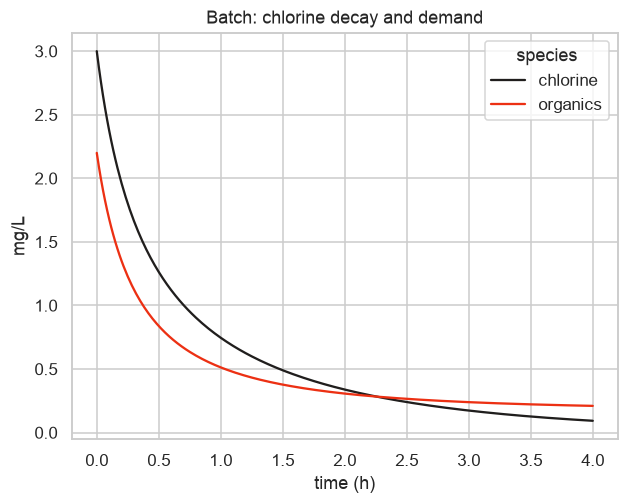

In [ ]:
frame = pd.DataFrame(
    {
        "time (h)": t_b / 3600,
        "chlorine": b["Cl.concentration"] / MG_L,
        "organics": b["Org.concentration"] / MG_L,
    }
).melt("time (h)", var_name="species", value_name="mg/L")
ax = sns.lineplot(data=frame, x="time (h)", y="mg/L", hue="species")
ax.set_title("Batch: chlorine decay and demand")

## Step 2. The contact tank as tanks in series

A serpentine tank approaches plug flow, and the classical model of that is N
stirred tanks in series. `TanksInSeries` builds them and connects them: the
outflow of each is the inflow of the next, one way. The effluent brings the
organics; the hypochlorite is dosed into the first cell. Both arrive as a `Dose`
(a molar flow). The outlets go to an `Accumulator`, which counts what leaves, so
the chlorine discharged per day is a state of the model.

In [ ]:
Q = 0.35  # m3/s
VOLUME = 4 * 650.0  # m3, residence time 2.1 h
ORG_IN = 2.2 * MG_L  # mol/m3 of chlorine-demanding organics in the effluent


def contact_tank(n_cells, dose_mol_s):
    reactions = [
        Reaction({"Cl": -1}, K_DECAY, name="decay"),
        Reaction({"Cl": -1, "Org": -1}, K_DEMAND, name="demand"),
    ]
    if n_cells == 1:
        tank = MixedReactor(VOLUME, Q, {"Cl": 0.0, "Org": ORG_IN}, reactions, name="tank")
    else:
        tank = TanksInSeries(
            n_cells, VOLUME, Q, {"Cl": 0.0, "Org": ORG_IN}, reactions, name="tank"
        )
    dose = Dose(dose_mol_s, name="hypochlorite")
    effluent = Dose(
        None, name="effluent_organics"
    )  # mol/s of organics arriving, an input
    discharged = Accumulator(name="discharged_cl")
    sink = Ground(name="outfall")
    s = otwin.System(tank, dose, effluent, discharged, sink)
    s.connect(dose.port, tank.in_Cl)
    s.connect(effluent.port, tank.in_Org)
    s.connect(tank.out_Cl, discharged.port)
    s.connect(tank.out_Org, sink.port)
    return otwin.compile(s), tank


DOSE = Q * 3.0 * MG_L  # start with 3.0 mg/L applied
t = np.arange(0, 12 * 3600 + 1, 60.0)
STEADY = {"effluent_organics": Q * ORG_IN}
serpentine, tank4 = contact_tank(4, DOSE)
print(f"{serpentine.n_states} states: 2 species in each of 4 cells, plus the accumulator")
run = serpentine.simulate(t=t, inputs=STEADY, solver="patankar")
outlet = run["tank.tank3.Cl.concentration"] / MG_L
print(
    f"applied dose 3.0 mg/L: outlet residual settles at {outlet[-1]:.2f} mg/L (limit 0.20); "
    f"chlorine discharged in the last 6 h: {(run['discharged_cl.amount'][-1] - run['discharged_cl.amount'][t.searchsorted(6 * 3600)]) * 70.9 / 1e3:.1f} kg"
)

9 states: 2 species in each of 4 cells, plus the accumulator
applied dose 3.0 mg/L: outlet residual settles at 0.47 mg/L (limit 0.20); chlorine discharged in the last 6 h: 3.5 kg


The model has nine states, named by cell: `tank.tank0.Cl.amount` to
`tank.tank3.Cl.amount`, the organics in each, and the accumulator. The outlet
residual is read from the last cell. The dose of 3.0 mg/L leaves a residual above
the permit; the next step finds the smallest dose that still does.

## Step 3. Find the dose, and compare mixing

Sweep the applied dose for the four-cell serpentine and for a single stirred
basin of the same volume, and read the steady outlet residual.

In [ ]:
rows = []
for n_cells in (1, 4):
    for applied in (1.5, 2.0, 2.5, 3.0, 3.5):
        m, tank = contact_tank(n_cells, Q * applied * MG_L)
        out = m.simulate(t=t, inputs=STEADY, solver="patankar")
        last = (
            f"tank.tank{n_cells - 1}.Cl.concentration"
            if n_cells > 1
            else "tank.Cl.concentration"
        )
        rows.append(
            {
                "cells": n_cells,
                "applied (mg/L)": applied,
                "outlet residual (mg/L)": out[last][-1] / MG_L,
                "meets 0.2 mg/L": bool(out[last][-1] >= LIMIT),
            }
        )
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
for n_cells in (1, 4):
    ok = table[(table.cells == n_cells) & table["meets 0.2 mg/L"]]
    print(
        f"{n_cells} cell(s): smallest applied dose in the sweep that meets the permit: {ok['applied (mg/L)'].min()} mg/L"
    )

 cells  applied (mg/L)  outlet residual (mg/L)  meets 0.2 mg/L
     1             1.5                   0.329            True
     1             2.0                   0.487            True
     1             2.5                   0.667            True
     1             3.0                   0.866            True
     1             3.5                   1.081            True
     4             1.5                   0.118           False
     4             2.0                   0.205            True
     4             2.5                   0.322            True
     4             3.0                   0.470            True
     4             3.5                   0.644            True
1 cell(s): smallest applied dose in the sweep that meets the permit: 1.5 mg/L
4 cell(s): smallest applied dose in the sweep that meets the permit: 2.0 mg/L


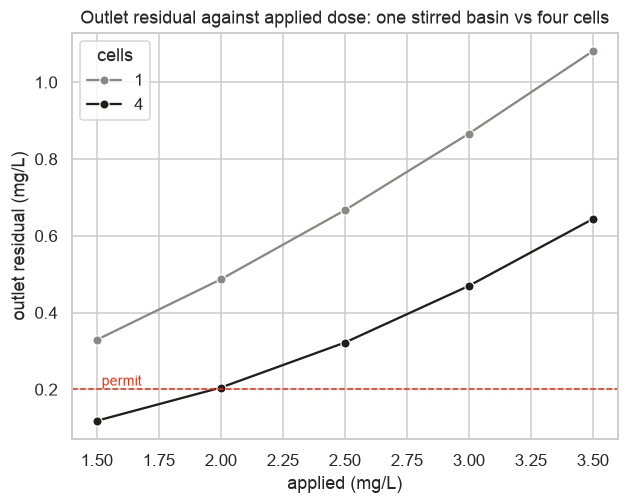

In [ ]:
ax = sns.lineplot(
    data=table,
    x="applied (mg/L)",
    y="outlet residual (mg/L)",
    hue="cells",
    marker="o",
    palette=["#8A8886", "#201E1D"],
)
ax.axhline(0.2, color="#EC3013", ls="--", lw=1)
ax.text(1.52, 0.21, "permit", color="#EC3013", fontsize=9)
ax.set_title("Outlet residual against applied dose: one stirred basin vs four cells")

For the same applied dose the serpentine leaves slightly *less* residual than
one stirred basin: in near plug flow the chlorine meets the organics at full
concentration, so more of both react, where a stirred basin dilutes the dose to
the outlet concentration at once. The outlet residual is therefore not why
contact tanks are built as serpentines. The reason is contact time: in plug flow
every parcel of water spends the full residence time with chlorine, while in a
stirred basin a share of the water leaves almost immediately. An outlet
concentration cannot show that; the next step shows the other consequence of
mixing, how the two tanks respond to a disturbance.

## Step 4. A storm

A storm flush triples the organics arriving for two hours, from 14:00 to 16:00 of
a day that starts with the tanks full of chlorine-free water. The dose stays at
the smallest value that met the permit for each configuration; the statistics
are taken once the tanks have settled, from hour 10.

 cells  dose (mg/L)  min residual (mg/L)  hours below permit
     1          1.5                0.158               2.117
     4          2.0                0.017               6.733


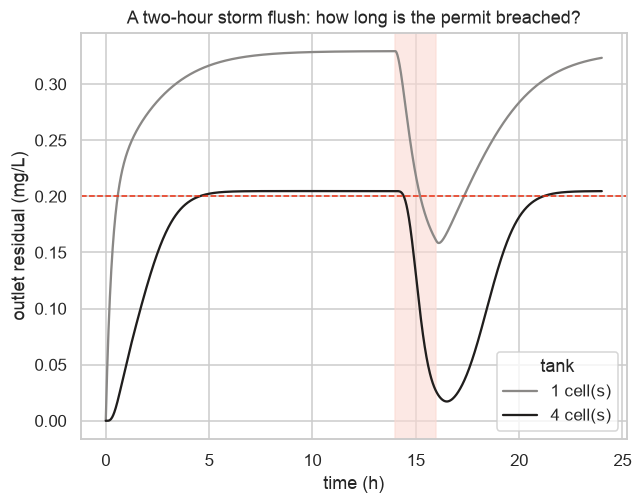

In [ ]:
def flush(time):
    return Q * ORG_IN * (3.0 if 14 * 3600 <= time < 16 * 3600 else 1.0)


t_day = np.arange(0, 24 * 3600 + 1, 60.0)
settled = t_day >= 10 * 3600
storm_rows, storm_traces = [], []
for n_cells in (1, 4):
    applied = table[(table.cells == n_cells) & table["meets 0.2 mg/L"]][
        "applied (mg/L)"
    ].min()
    m, tank = contact_tank(n_cells, Q * applied * MG_L)
    out = m.simulate(t=t_day, inputs={"effluent_organics": flush}, solver="patankar")
    last = (
        f"tank.tank{n_cells - 1}.Cl.concentration"
        if n_cells > 1
        else "tank.Cl.concentration"
    )
    residual = out[last] / MG_L
    below = (residual < 0.2) & settled
    storm_rows.append(
        {
            "cells": n_cells,
            "dose (mg/L)": applied,
            "min residual (mg/L)": residual[settled].min(),
            "hours below permit": below.sum() * 60 / 3600,
        }
    )
    storm_traces.append(
        pd.DataFrame(
            {
                "time (h)": t_day / 3600,
                "outlet residual (mg/L)": residual,
                "tank": f"{n_cells} cell(s)",
            }
        )
    )
print(pd.DataFrame(storm_rows).round(3).to_string(index=False))
ax = sns.lineplot(
    data=pd.concat(storm_traces),
    x="time (h)",
    y="outlet residual (mg/L)",
    hue="tank",
    palette=["#8A8886", "#201E1D"],
)
ax.axhline(0.2, color="#EC3013", ls="--", lw=1)
ax.axvspan(14, 16, color="#FBD9D2", alpha=0.6)
ax.set_title("A two-hour storm flush: how long is the permit breached?")

The stirred basin reacts at once and shallowly; the serpentine responds with a
delay of about the residence time and more sharply, because the slug of organics
travels through it as a front. The table gives, for each, the lowest residual
and the hours below the permit; how deep and how long depends on the margin the
dose left in steady state. This is the kind of question a twin answers daily:
given what is arriving, when does the outlet breach, and for how long.

## Step 5. Why `patankar`

Chemical rates can be fast relative to a convenient time step. A general
integrator then produces negative amounts, and nothing in the energy audit
notices, because the storage function is even in the amount. The `patankar`
solver scales every reaction by one implicit factor and cannot go negative, and
it keeps every mass balance exact. Here is first-order decay alone with a
six-hour step, k·dt = 2.4, against its closed form.

In [ ]:
cl_only = Species(1.0, concentration=3.0 * MG_L, name="Cl")
decay_only = Reaction({"Cl": -1}, K_DECAY, name="decay")
s_only = otwin.System(cl_only, decay_only)
s_only.connect(cl_only.port, decay_only.Cl)
decay_model = otwin.compile(s_only)
coarse = np.arange(0, 24 * 3600 + 1, 6 * 3600.0)
rows = []
for solver in ("euler", "midpoint", "rk4", "patankar"):
    out = decay_model.simulate(t=coarse, solver=solver)
    rows.append(
        {
            "solver": solver,
            "min chlorine (mg/L)": out["Cl.concentration"].min() / MG_L,
            "chlorine at 24 h (mg/L)": out["Cl.concentration"][-1] / MG_L,
        }
    )
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"closed form at 24 h: {3.0 * np.exp(-K_DECAY * 24 * 3600):.4f} mg/L")

  solver  min chlorine (mg/L)  chlorine at 24 h (mg/L)
   euler              -4.2000                  -4.2000
midpoint              -0.2727                  -0.2727
     rk4              -0.6000                  -0.6000
patankar               0.0224                   0.0224
closed form at 24 h: 0.0002 mg/L


Euler and the implicit midpoint go negative at this step; RK4 happens to stay
positive here (it does until k·dt ≈ 2.8); `patankar` is non-negative at any
step by construction, and monotone. None is accurate at k·dt = 2.4: it is first
order, so use a reasonable step for accuracy, and use it for safety.

## What to take from this

- Chemistry is built from the same two ideas as the other domains: a species is a
  storage, a reaction connects species at a rate, and the compiler writes the
  mass balances.
- `MixedReactor` and `TanksInSeries` are composites of species, reactions and
  outflows; the plug-flow approximation is a matter of the number of cells.
- Simulate chemistry with `solver="patankar"`.
- A stirred basin and a plug-flow train differ less at steady state than in how
  they respond to a disturbance.

Next: [Tutorial 7](07_heated_building.md) moves to heat.